# Figure 5 — in multitask networks, the relationship between two tasks sets the TI / TD mix and the transfer

One cell per panel; the plotting function is defined inside the cell so a panel can be changed on its own. Panel **a** is an
Illustrator schematic. Every panel reads stored results; nothing is trained or refitted (runtime ~1 min).

| panel | content | output |
|---|---|---|
| b | the 27 tasks and the four task pair types; one example pair per type | `fig5_b_pair_type_matrix.svg`, `fig5_b_pair_type_examples.svg` |
| c | cross-task generalization index: all task pairs pooled, then one example pair of each type (one 7-in row, shared y) | `fig5_c_index_hist_row.svg` |
| d | % TI and % TD of a pair's choice units, by pair type | `fig5_d_pct_ti_td_by_type.svg` |
| e | population across-task decoding, by pair type | `fig5_e_across_by_type.svg` |
| f | % TI vs across-task decoding, one point per task pair (as Fig 4 g / m) | `fig5_f_pct_ti_vs_across.svg` |
| g | size-matched TD-only / random / TI-only across-task decoding, by pair type (as Fig 4 h / n) | `fig5_g_three_point_by_type.svg` |
| d–g | the four panels as one 7-in row | `fig5_dg_row.svg` |

**Networks:** 10 ReLU networks (Yang et al. 2019 architecture, 256 units), shared output ring, trained on all 27 tasks
interleaved for 20,000 steps of 64 trials.

**Stored results:** `results/readout/main_relu/` and `results/performance/main_relu/perf.csv`.
- `units.parquet`: the index of every unit in every task pair.
- `pairs.parquet`: pair-level decoding.
- `heldout_pairs_p90.parquet`: labels from one trial half, decoding on the other (0.90 exclusion).

**Regenerating the stored results (not needed for this notebook):** training the 10 networks takes ~3.5 h on an Apple M-series GPU, then
the read-outs run (see the repository `README.md`; `scripts/run_readouts.sh main` runs steps 2-4):
1. `python -m mtrnn.train --config configs/main_relu.json`
2. `python -m mtrnn.evaluate main_relu`
3. `python -m mtrnn.readout all main_relu`
4. `python -m mtrnn.heldout main_relu --min_perf 0.9`

**Definitions:**
- A unit enters a task pair if it carries the choice in at least one of the two tasks (within-task accuracy ≥ 0.55).
- TI / TD = top / bottom 20 % of the index pooled over all pairs and networks (cuts 0.481 / 0.634).
- A network is left out of every pair containing a task it performs below 0.90 (Yang et al. 2019's criterion, applied per
  network-task combination). This drops 12 of 270 network-task combinations: DNMS in 9 networks, Match in 2, DMC in 1. DNMS pairs
  therefore rest on one network. The supplements (Figures S7 and S8, `figure_s7.ipynb`, `figure_s8.ipynb`) use the same rule.

## Fig 5 a · network and readouts (Illustrator schematic); setup

In [1]:
# ── setup: stored multitask-RNN results, pair types, paper colours ──
import os, sys
sys.path.insert(0, os.getcwd())                 # run from analysis/: paper_style.py, paper_stats.py, figure_layout.py
from paper_style import *                       # colours, rcParams, figure_dir; puts ROOT on sys.path
apply_style()                                   # the setup scripts set their own rcParams
from paper_stats import StatsTable
ST = StatsTable('figure_5')          # Supplementary Table 1 rows (Fig. 5)
ST.schematic('a')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, FancyArrowPatch
from matplotlib.colors import ListedColormap
from scipy.stats import linregress, wilcoxon
from mtrnn import readout as Q
fig_dir = figure_dir('figure_5')
def save(fname):
    # a panel (or, for b, a part) with a slot in layouts/figure_5.json is fitted to it and saved on a fixed canvas; the others
    # (b's example column, the d-g row) keep the tight bbox
    kw = {}
    try:
        fit_panel(plt.gcf(), 'figure_5', fname.split('_')[1])
    except KeyError:
        try:
            fit_panel(plt.gcf(), 'figure_5', fname.split('_')[1], part=fname)
        except KeyError:
            kw = dict(bbox_inches='tight')
    plt.savefig(fig_dir + fname + '.svg', dpi=800, facecolor='white', edgecolor='none', **kw)

RUN = 'main_relu'
TYPES = ['same operation', 'different operation', 'spatial vs abstract', 'reversed mapping']
TYPE_LAB = {'same operation': 'Same task family', 'different operation': 'Different task family',
            'spatial vs abstract': 'Spatial vs abstract response', 'reversed mapping': 'Reversed mapping'}
TYPE_TICK = {'same operation': 'Same\nfam.', 'different operation': 'Diff.\nfam.', 'spatial vs abstract': 'Spat. vs\nabstr.', 'reversed mapping': 'Rev.\nmap.'}
TYPE_C = {'same operation': '#2F6DB5', 'different operation': '#8DB8E8', 'spatial vs abstract': '#9C6ADE', 'reversed mapping': '#E8412C'}
FAM_ORDER = [('Go', ['Go', 'RT Go', 'Dly Go', 'Go Mod1', 'Go Mod2', 'Sac']), ('Anti', ['Anti', 'RT Anti', 'Dly Anti']),
             ('Decision', ['DM 1', 'DM 2', 'Ctx DM 1', 'Ctx DM 2', 'MultSen DM']),
             ('Delayed decision', ['Dly DM 1', 'Dly DM 2', 'Ctx Dly DM 1', 'Ctx Dly DM 2', 'MultSen Dly DM']),
             ('Matching', ['DMS', 'DNMS', 'DMC', 'DNMC']), ('Pursuit', ['Pursuit']), ('Yes / no', ['Cat', 'Cat-B', 'Match'])]
TASK_ORDER = [t for _, ts in FAM_ORDER for t in ts]
PANEL_SIZE = (1.75, 1.6)

# pair-level and unit-level tables; a network is left out of a pair if it performs either task below 0.90
tp = Q.task_perf(RUN)
MIN_PERF = 0.90
ok = lambda s, a, b: tp[(int(s), a)] >= MIN_PERF and tp[(int(s), b)] >= MIN_PERF
H = pd.read_parquet(os.path.join(Q.OUT, RUN, 'heldout_pairs_p90.parquet')); H['type'] = [Q.relation(a, b, 'shared') for a, b in zip(H.task_a, H.task_b)]
P = pd.read_parquet(os.path.join(Q.OUT, RUN, 'pairs.parquet')); P = P[P.primary]
P = P[[ok(s, a, b) for s, a, b in zip(P.seed, P.task_a, P.task_b)]]; P['type'] = [Q.relation(a, b, 'shared') for a, b in zip(P.task_a, P.task_b)]
U = pd.read_parquet(os.path.join(Q.OUT, RUN, 'units.parquet'))
U = U.merge(P[['task_a', 'task_b', 'window', 'seed', 'type']], on=['task_a', 'task_b', 'window', 'seed']); U = U[U.group]   # choice units of each pair
TD_CUT, TI_CUT = U.snCCGP.quantile(.2), U.snCCGP.quantile(.8)
U['cls_ti'] = np.where(U.snCCGP >= TI_CUT, 'TI', np.where(U.snCCGP <= TD_CUT, 'TD', 'Int'))

stars = lambda p: 'ns' if not p < .05 else ('***' if p < .001 else ('**' if p < .01 else '*'))
def net_dots(ax, x, v, c, rng, width=.1, ms=3):
    # open circles = networks, filled = mean ± SEM
    v = np.asarray(v, float); v = v[np.isfinite(v)]
    ax.scatter(x + rng.uniform(-width, width, len(v)), v, s=ms, facecolor='white', edgecolor=c, lw=.5, alpha=.85, zorder=2)
    ax.errorbar(x, v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt='o', ms=3.2, color=c, capsize=0, elinewidth=.8, zorder=3)
def mean_sem(ax, x, v, c, ms=3.2):
    v = np.asarray(v, float); v = v[np.isfinite(v)]
    ax.errorbar(x, v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt='o', ms=ms, color=c, capsize=0, elinewidth=.8, zorder=4)
def type_axis(ax):
    ax.set_xticks(range(len(TYPES))); ax.set_xticklabels([TYPE_TICK[t] for t in TYPES], fontsize=FS_TICK)
    for lab, t in zip(ax.get_xticklabels(), TYPES): lab.set_color(TYPE_C[t])
    ax.set_xlim(-.6, len(TYPES) - .4); ax.tick_params(axis='x', length=0, pad=2)
def top_legend(ax, handles, labels):
    ax.legend(handles, labels, frameon=False, fontsize=FS_LEGEND, loc='lower left', bbox_to_anchor=(0, 1.0), handletextpad=.1, borderaxespad=0, ncol=len(labels), columnspacing=.6)
def single(panel, fname, size=PANEL_SIZE):
    # one panel on its own axes, same size as in the row
    fig, ax = plt.subplots(figsize=size); panel(ax); ax.tick_params(labelsize=FS_TICK); save(fname); plt.show()

print(f'{U.seed.nunique()} networks, {len(P)} (pair, network) rows, {len(U):,} unit-pairs; cuts TD <= {TD_CUT:.3f}, TI >= {TI_CUT:.3f}')
print('pairs per type:', pd.Series([Q.relation(a, b, 'shared') for i, a in enumerate(TASK_ORDER) for b in TASK_ORDER[:i]]).value_counts().reindex(TYPES).to_dict())

10 networks, 3201 (pair, network) rows, 535,965 unit-pairs; cuts TD <= 0.481, TI >= 0.634
pairs per type: {'same operation': 45, 'different operation': 171, 'spatial vs abstract': 72, 'reversed mapping': 63}


## Fig 5 b · the 27 tasks and the four task pair types

**Left:** the tasks, grouped by family; each cell is one pair, coloured by how the two tasks relate.
- **Same task family:** the same operation, differing in timing, cue modality or context (Go vs Dly Go; Go Mod1 vs Go Mod2).
- **Different task family:** a different operation, but both answer toward a stimulus direction (Go vs DM 1).
- **Spatial vs abstract response:** one task answers toward a direction, the other with a fixed yes / no target (Go vs Cat).
- **Reversed mapping:** one task answers toward the stimulus, the other away from it (Go vs Anti).

**Right:** one example pair per type on the response circle (grey dot = stimulus, arrow = the correct response).

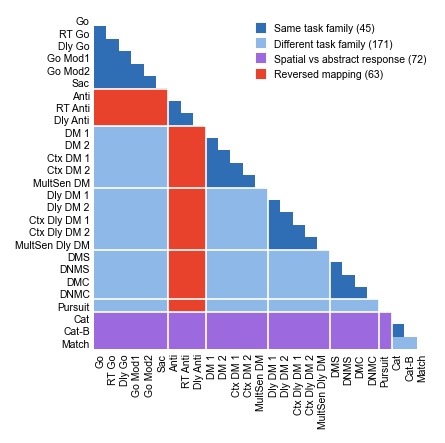

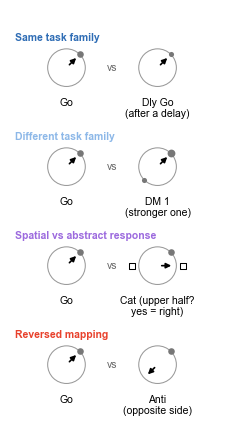

In [2]:
def plot_pair_matrix(fname='fig5_b_pair_type_matrix'):
    n = len(TASK_ORDER); M = np.full((n, n), np.nan); codes = {t: i for i, t in enumerate(TYPES)}
    for i, a in enumerate(TASK_ORDER):
        for j, b in enumerate(TASK_ORDER):
            if j < i: M[i, j] = codes[Q.relation(a, b, 'shared')]
    fig, ax = plt.subplots(figsize=(2.9, 2.9))
    ax.imshow(M, cmap=ListedColormap([TYPE_C[t] for t in TYPES]), vmin=-.5, vmax=3.5, interpolation='nearest')
    ax.set_xticks(range(n)); ax.set_yticks(range(n)); ax.set_xticklabels(TASK_ORDER, rotation=90, fontsize=FS_TICK); ax.set_yticklabels(TASK_ORDER, fontsize=FS_TICK)
    k = 0
    for _, ts in FAM_ORDER[:-1]:
        k += len(ts); ax.axhline(k - .5, color='white', lw=.8); ax.axvline(k - .5, color='white', lw=.8)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(length=0)
    cnt = pd.Series([Q.relation(a, b, 'shared') for i, a in enumerate(TASK_ORDER) for b in TASK_ORDER[:i]]).value_counts()
    ST.value('b', int(cnt.sum()), dataset='ReLU networks', measure='Task pairs', group='all pairs', n=int(cnt.sum()), unit='task pairs')
    for t in TYPES:
        ST.value('b', int(cnt[t]), dataset=TYPE_LAB[t], measure='Task pairs', group='pairs of this type', n=int(cnt[t]), unit='task pairs')
    ax.legend([Line2D([], [], marker='s', ls='', color=TYPE_C[t], ms=4) for t in TYPES], [f'{TYPE_LAB[t]} ({cnt[t]})' for t in TYPES],
              frameon=False, fontsize=FS_LEGEND, loc='upper right', bbox_to_anchor=(1.02, 1.0), handletextpad=.2)
    save(fname); plt.show()

def draw_trial(ax, x, y, stims, resp, label, yesno=False, r=1.0):
    # response circle: grey dots = stimuli (size = strength), squares = yes / no targets, arrow = correct response
    ax.add_patch(Circle((x, y), r, fc='none', ec='#999999', lw=.5))
    for (ang, s) in stims:
        ax.scatter(x + r * np.cos(np.deg2rad(ang)), y + r * np.sin(np.deg2rad(ang)), s=10 * s, color='#777777', zorder=3, lw=0)
    if yesno:
        for ang in (0, 180): ax.scatter(x + 1.35 * r * np.cos(np.deg2rad(ang)), y, s=6, marker='s', facecolor='white', edgecolor='k', lw=.5, zorder=3)
    ax.add_patch(FancyArrowPatch((x, y), (x + .95 * r * np.cos(np.deg2rad(resp)), y + .95 * r * np.sin(np.deg2rad(resp))), arrowstyle='-|>', mutation_scale=5, color='k', lw=.8))
    ax.text(x, y - 1.55 * r, label, fontsize=FS_ANNOT, ha='center', va='top')

def plot_pair_examples(fname='fig5_b_pair_type_examples'):
    fig, ax = plt.subplots(figsize=(2.3, 3.6)); ax.set_xlim(0, 10); ax.set_ylim(0, 21); ax.axis('off'); ax.set_aspect('equal')
    rows = [('same operation', [([(45, 1)], 45, 'Go', False), ([(45, .6)], 45, 'Dly Go\n(after a delay)', False)]),
            ('different operation', [([(45, 1)], 45, 'Go', False), ([(45, 1.4), (225, .6)], 45, 'DM 1\n(stronger one)', False)]),
            ('spatial vs abstract', [([(45, 1)], 45, 'Go', False), ([(45, 1)], 0, 'Cat (upper half?\nyes = right)', True)]),
            ('reversed mapping', [([(45, 1)], 45, 'Go', False), ([(45, 1)], 225, 'Anti\n(opposite side)', False)])]
    for i, (t, trials) in enumerate(rows):
        y = 18.3 - i * 5.0
        ax.text(0.0, y + 1.55, TYPE_LAB[t], fontsize=FS_ANNOT, color=TYPE_C[t], weight='bold', va='center')
        for j, (stims, resp, lab, yn) in enumerate(trials):
            draw_trial(ax, 2.6 + j * 4.6, y, stims, resp, lab, yesno=yn, r=.95)
        ax.text(4.9, y, 'vs', fontsize=FS_ANNOT, ha='center', va='center', color='#666666')
    save(fname); plt.show()

plot_pair_matrix(); plot_pair_examples()

## Fig 5 c · the cross-task generalization index, pooled and in one example pair of each type

**Left:** every choice unit of the 10 networks in all 351 task pairs (a unit counts once per pair it enters).

**Right:** one example pair of each type from network 0, the pairs drawn in b. Network 0 was chosen because its four pairs sit
closest to the average TI / TD mix of their type.

All panels: density, same bins and shared y axis; stacked TD / Int / TI using the pooled cuts; dotted line = median.

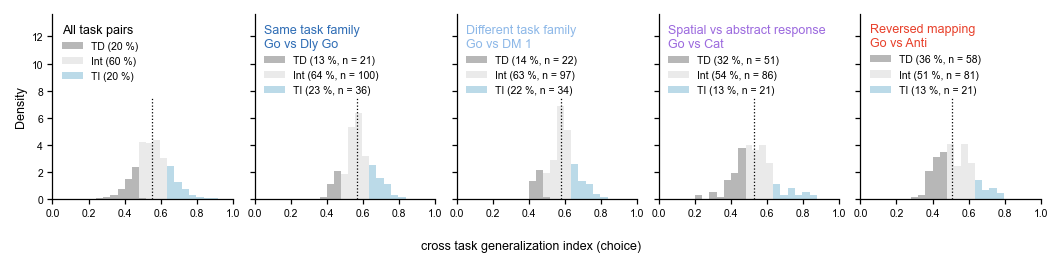

  All task pairs (10 networks): n = 535,965; TD 20.2 %, Int 59.7 %, TI 20.1 %; median 0.553
  Same task family (Go vs Dly Go, network 0): n = 157; TD 13.4 %, Int 63.7 %, TI 22.9 %; median 0.568
  Different task family (Go vs DM 1, network 0): n = 153; TD 14.4 %, Int 63.4 %, TI 22.2 %; median 0.578
  Spatial vs abstract response (Go vs Cat, network 0): n = 158; TD 32.3 %, Int 54.4 %, TI 13.3 %; median 0.529
  Reversed mapping (Go vs Anti, network 0): n = 160; TD 36.2 %, Int 50.6 %, TI 13.1 %; median 0.509


In [3]:
HIST_SEED = 0
TYPE_PAIRS = [('same operation', ('Go', 'Dly Go')), ('different operation', ('Go', 'DM 1')), ('spatial vs abstract', ('Go', 'Cat')), ('reversed mapping', ('Go', 'Anti'))]

def plot_index_hist_row(seed=HIST_SEED, bin_w=0.04, fname='fig5_c_index_hist_row'):
    lo, hi, w = .0, 1.0, bin_w
    below = np.linspace(lo, TD_CUT, max(int(round((TD_CUT - lo) / w)), 1) + 1); mid = np.linspace(TD_CUT, TI_CUT, max(int(round((TI_CUT - TD_CUT) / w)), 1) + 1)
    above = np.linspace(TI_CUT, hi, max(int(round((hi - TI_CUT) / w)), 1) + 1); bins = np.unique(np.concatenate([below, mid, above]))
    panels = [('All task pairs', None, U)] + [(TYPE_LAB[t], pr, U[(U.task_a == pr[0]) & (U.task_b == pr[1]) & (U.seed == seed)]) for t, pr in TYPE_PAIRS]
    cols = ['k'] + [TYPE_C[t] for t, _ in TYPE_PAIRS]
    top = max(np.histogram(d.snCCGP.clip(lo, hi), bins, density=True)[0].max() for _, _, d in panels)
    fig, axs = plt.subplots(1, 5, figsize=(7.0, 1.6), sharey=True, gridspec_kw=dict(wspace=.12)); order = ('TD', 'Int', 'TI')
    for ax, (lab, pr, d), col in zip(axs, panels, cols):
        x = [d.loc[d.cls_ti == c, 'snCCGP'].clip(lo, hi).values for c in order]
        ax.hist(x, bins=bins, stacked=True, density=True, edgecolor='none', alpha=.3, color=[CLS_COL[c] for c in order],
                label=[f'{c} ({100 * len(a) / len(d):.0f} %' + (f', n = {len(a)})' if pr is not None else ')') for c, a in zip(order, x)])
        ax.axvline(float(np.nanmedian(d.snCCGP)), ymax=.55, color='k', lw=.6, ls=':')
        ax.set_xlim(0, 1.0); ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0]); ax.set_ylim(0, top * 2.0); ax.tick_params(labelsize=FS_TICK)
        ax.legend(frameon=False, fontsize=FS_LEGEND, loc='upper left', title=lab if pr is None else f'{lab}\n{pr[0]} vs {pr[1]}', title_fontsize=FS_TITLE, alignment='left')
        ax.get_legend().get_title().set_color(col)
    axs[0].set_ylabel('Density', fontsize=FS_LABEL)
    fig.text(.5, -.06, 'cross task generalization index (choice)', ha='center', va='top', fontsize=FS_LABEL)
    save(fname); plt.show()
    for (lab, pr, d) in panels:
        print(f'  {lab}' + (f' ({pr[0]} vs {pr[1]}, network {seed})' if pr else ' (10 networks)') + f': n = {len(d):,}; '
              + ', '.join(f'{c} {100 * np.mean(d.cls_ti == c):.1f} %' for c in order) + f'; median {np.median(d.snCCGP):.3f}')
        ds = 'ReLU networks, all task pairs' if pr is None else f'{lab} ({pr[0]} vs {pr[1]}, network {seed})'
        for c in order:
            ST.value('c', 100 * np.mean(d.cls_ti == c), dataset=ds, measure='% of choice units', group=c, n=len(d),
                     unit='unit × task pair' if pr is None else 'choice units')

plot_index_hist_row()

## Fig 5 d · % TI and % TD by pair type

For each network: the share of each pair's choice units in the TI and TD tails (cuts from c), averaged over the pairs of a type.
- Points: open circles = networks, joined by grey lines; filled = mean ± SEM; dotted line = 20 %.
- Stars: TD vs TI, paired Wilcoxon over the 10 networks. With n = 10 the smallest possible p is 0.002 (\*\*).
- The printout repeats the test over task pairs.

  Same task family: TI 26.4 ± 0.6 %, TD 11.2 ± 0.4 %; networks p = 0.00195; pairs (n = 45) TD > TI in 2 %, p = 2.4e-12
  Different task family: TI 23.0 ± 0.6 %, TD 13.8 ± 0.3 %; networks p = 0.00195; pairs (n = 171) TD > TI in 8 %, p = 3.3e-28
  Spatial vs abstract response: TI 16.0 ± 0.6 %, TD 28.1 ± 0.8 %; networks p = 0.00195; pairs (n = 72) TD > TI in 100 %, p = 1.7e-13
  Reversed mapping: TI 13.7 ± 1.2 %, TD 33.0 ± 1.9 %; networks p = 0.00195; pairs (n = 63) TD > TI in 100 %, p = 5.2e-12


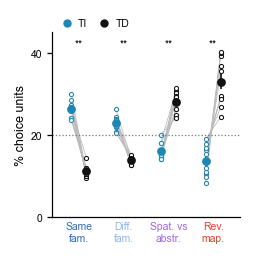

In [4]:
def pct_by_type():
    f = U.groupby(['seed', 'task_a', 'task_b', 'type']).cls_ti.agg(TI=lambda s: 100 * (s == 'TI').mean(), TD=lambda s: 100 * (s == 'TD').mean()).reset_index()
    return f.groupby(['seed', 'type'])[['TI', 'TD']].mean().reset_index(), f

def panel_d(ax, verbose=True):
    W, F = pct_by_type()
    for i, t in enumerate(TYPES):
        g = W[W.type == t]; xs = {'TI': i - .17, 'TD': i + .17}
        for _, r in g.iterrows(): ax.plot([xs['TI'], xs['TD']], [r.TI, r.TD], color='#BBBBBB', lw=.4, zorder=1)
        for cls in ('TI', 'TD'):
            ax.scatter(np.full(len(g), xs[cls]), g[cls], s=4, facecolor='white', edgecolor=CLS_COL[cls], lw=.5, zorder=2)
            mean_sem(ax, xs[cls], g[cls], CLS_COL[cls])
        ax.text(i, 41, stars(wilcoxon(g.TD, g.TI).pvalue), ha='center', va='bottom', fontsize=FS_ANNOT)
        for cls in ('TI', 'TD'):
            ST.group('d', g[cls], dataset=TYPE_LAB[t], measure='% choice units', group=cls, unit='networks')
        ST.paired('d', g.TD, g.TI, test='wilcoxon', dataset=TYPE_LAB[t], measure='% choice units', comparison='TD vs TI', unit='networks',
                  expect_p=wilcoxon(g.TD, g.TI).pvalue)
    ax.axhline(20, color='#777777', ls=':', lw=.6)
    ax.set_ylim(0, 45); ax.set_yticks([0, 20, 40]); ax.set_ylabel('% choice units', fontsize=FS_LABEL); type_axis(ax)
    top_legend(ax, [Line2D([], [], marker='o', ls='', color=CLS_COL[c], ms=3) for c in ('TI', 'TD')], ['TI', 'TD'])
    if verbose:
        for t in TYPES:
            g = W[W.type == t]; f = F[F.type == t].groupby(['task_a', 'task_b'])[['TI', 'TD']].mean()
            print(f'  {TYPE_LAB[t]}: TI {g.TI.mean():.1f} ± {g.TI.sem():.1f} %, TD {g.TD.mean():.1f} ± {g.TD.sem():.1f} %; networks p = {wilcoxon(g.TD, g.TI).pvalue:.3g}; '
                  f'pairs (n = {len(f)}) TD > TI in {100 * np.mean(f.TD > f.TI):.0f} %, p = {wilcoxon(f.TD, f.TI).pvalue:.1e}')

single(panel_d, 'fig5_d_pct_ti_td_by_type')

## Fig 5 e · population across-task decoding, by pair type

All choice units of a pair. The paper's coding-direction decoder is trained on one task and tested on the other (both directions
averaged), with labels and decoding on separate trial halves. Points: open = networks (mean over that network's pairs of the
type); filled = mean ± SEM.

  Same task family 0.987 ± 0.002; Different task family 0.986 ± 0.003; Spatial vs abstract response 0.876 ± 0.011; Reversed mapping 0.808 ± 0.042


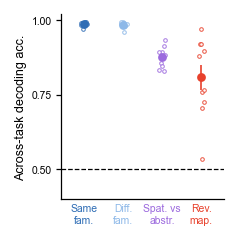

In [5]:
def panel_e(ax, verbose=True):
    W = H.groupby(['seed', 'type']).across.mean().reset_index(); rng = np.random.default_rng(2)
    for i, t in enumerate(TYPES):
        net_dots(ax, i, W[W.type == t].across, TYPE_C[t], rng)
        ST.group('e', W[W.type == t].across, dataset=TYPE_LAB[t], measure='Across-task accuracy', group='all choice units', unit='networks')
    ax.axhline(.5, color='k', ls='--', lw=.6); ax.set_ylim(.4, 1.02); ax.set_yticks([.5, .75, 1.0]); ax.set_ylabel('Across-task decoding acc.', fontsize=FS_LABEL); type_axis(ax)
    if verbose: print('  ' + '; '.join(f'{TYPE_LAB[t]} {W[W.type == t].across.mean():.3f} ± {W[W.type == t].across.sem():.3f}' for t in TYPES))

single(panel_e, 'fig5_e_across_by_type')

## Fig 5 f · % TI vs across-task decoding

As Figure 4 e / h, with task pairs in place of sessions: one point per task pair (mean over networks), coloured by type. The TI
labels come from one trial half and the across-task accuracy from the other. Line = least-squares fit.

  n = 351 pairs, slope per 10 % TI +0.109, r = +0.75, p = 1.2e-65


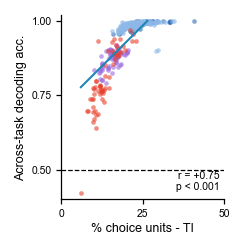

In [6]:
def panel_f(ax, verbose=True):
    d = H.groupby(['task_a', 'task_b', 'type']).mean(numeric_only=True).reset_index(); gg = d[np.isfinite(d.across) & np.isfinite(d.pct_TI)]
    for t in TYPES:
        g = gg[gg.type == t]; ax.scatter(g.pct_TI, g.across, s=5, color=TYPE_C[t], alpha=.6, lw=0)
    ST.corr('f', gg.pct_TI, gg.across, method='pearson', dataset='ReLU networks', measure='Across-task accuracy',
            comparison='% TI vs across-task accuracy', unit='task pairs', expect_p=linregress(gg.pct_TI, gg.across).pvalue)
    sl, ic, r, p, se = linregress(gg.pct_TI, gg.across); xl = np.linspace(gg.pct_TI.min(), gg.pct_TI.max(), 100); yl = ic + sl * xl; k = yl <= 1.0
    ax.plot(xl[k], yl[k], color=CLS_COL['TI'], lw=1.0); ax.axhline(.5, color='k', ls='--', lw=.6)
    ax.text(.97, .04, f'r = {r:+.2f}\n' + ('p < 0.001' if p < .001 else f'p = {p:.2g}'), transform=ax.transAxes, ha='right', va='bottom', fontsize=FS_ANNOT)
    ax.set_xlim(0, 50); ax.set_xticks([0, 25, 50]); ax.set_ylim(.4, 1.02); ax.set_yticks([.5, .75, 1.0])
    ax.set_xlabel('% choice units - TI', fontsize=FS_LABEL); ax.set_ylabel('Across-task decoding acc.', fontsize=FS_LABEL)
    if verbose: print(f'  n = {len(gg)} pairs, slope per 10 % TI {10 * sl:+.3f}, r = {r:+.2f}, p = {p:.1e}')

single(panel_f, 'fig5_f_pct_ti_vs_across')

## Fig 5 g · TD-only, random and TI-only populations, by pair type

As Figure 4 h / n. Size-matched populations: n = the smaller of the pair's TI and TD counts (at least 6), 5 draws. Labels come from
one trial half and decoding from the other; "random" draws from all of the pair's choice units. Thin lines = networks (mean over
the network's pairs of the type); dots = mean ± SEM. The printout gives the Wilcoxon test against random over task pairs.

  Same task family: TD 0.376 ± 0.007, random 0.864 ± 0.004, TI 0.956 ± 0.003; TD vs random p = 1.1e-13, TI vs random p = 1.1e-13 (44 pairs)
  Different task family: TD 0.368 ± 0.006, random 0.873 ± 0.004, TI 0.971 ± 0.003; TD vs random p = 8.2e-30, TI vs random p = 8.2e-30 (171 pairs)
  Spatial vs abstract response: TD 0.198 ± 0.009, random 0.757 ± 0.014, TI 0.953 ± 0.004; TD vs random p = 1.7e-13, TI vs random p = 1.7e-13 (72 pairs)
  Reversed mapping: TD 0.225 ± 0.006, random 0.677 ± 0.030, TI 0.956 ± 0.007; TD vs random p = 5.2e-12, TI vs random p = 5.2e-12 (63 pairs)


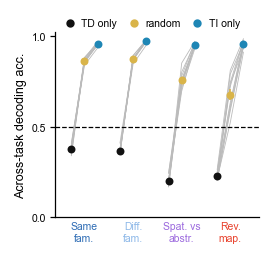

In [7]:
def panel_g(ax, order=('TD', 'random', 'TI'), verbose=True):
    off = dict(zip(order, (-.27, 0, .27)))
    for i, t in enumerate(TYPES):
        W = H[H.type == t].groupby('seed')[[f'{p}_across' for p in order]].mean().dropna(); W.columns = list(order)
        Pp = H[H.type == t].groupby(['task_a', 'task_b'])[[f'{p}_across' for p in order]].mean().dropna(); Pp.columns = list(order)
        for _, r in W.iterrows(): ax.plot([i + off[p] for p in order], r.values, color='#BBBBBB', lw=.4, zorder=1)
        for p in order: mean_sem(ax, i + off[p], W[p], POP_C[p], ms=2.8)
        for p in order:
            ST.group('g', W[p], dataset=TYPE_LAB[t], measure='Across-task accuracy', group=p if p == 'random' else f'{p}-only', unit='networks')
        if verbose: print(f'  {TYPE_LAB[t]}: ' + ', '.join(f'{p} {W[p].mean():.3f} ± {W[p].sem():.3f}' for p in order)
                          + f'; TD vs random p = {wilcoxon(Pp.TD, Pp.random).pvalue:.1e}, TI vs random p = {wilcoxon(Pp.TI, Pp.random).pvalue:.1e} ({len(Pp)} pairs)')
    ax.axhline(.5, color='k', ls='--', lw=.6); ax.set_ylim(0, 1.02); ax.set_yticks([0, .5, 1.0]); ax.set_ylabel('Across-task decoding acc.', fontsize=FS_LABEL); type_axis(ax)
    top_legend(ax, [Line2D([], [], marker='o', ls='', color=POP_C[p], ms=3) for p in order], ['TD only', 'random', 'TI only'])

single(panel_g, 'fig5_g_three_point_by_type', size=(2.0, 1.6))

## Fig 5 d–g · the four panels as one 7-in row

The same panel functions, drawn side by side at the widths used in the figure.

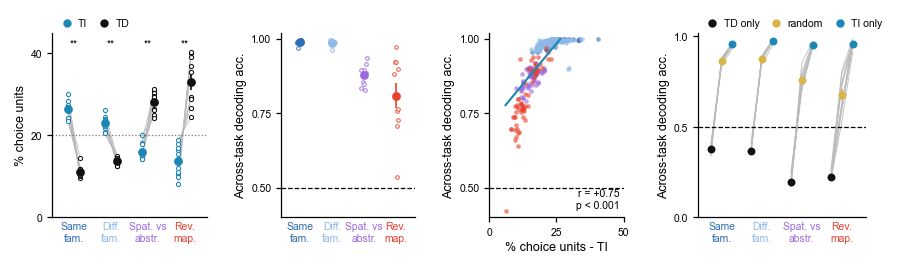

In [8]:
def plot_row_dg(fname='fig5_dg_row'):
    fig, axs = plt.subplots(1, 4, figsize=(7.0, 1.6), gridspec_kw=dict(wspace=.5, width_ratios=[1.15, 1, 1, 1.25]))
    for ax, panel in zip(axs, (panel_d, panel_e, panel_f, panel_g)): panel(ax, verbose=False); ax.tick_params(labelsize=FS_TICK)
    save(fname); plt.show()

plot_row_dg()

In [9]:
# Supplementary Table 1: write tables/fig5.csv
ST.save()

Fig. 5: 50 rows -> analysis/tables/fig5.csv
  rows per panel: a 1, b 5, c 15, d 12, e 4, f 1, g 12


,Panel,Dataset,Measure,Group / comparison,n,Unit of n,Mean,s.e.m.,Test,Statistic,P,Notebook location
0,a,None,schematic,None,<NA>,None,NaN,NaN,None,None,NaN,"figure_5.ipynb, cell 2 (Fig 5 a · network and ..."
1,b,ReLU networks,Task pairs,all pairs,351,task pairs,351.000000,NaN,None,None,NaN,"figure_5.ipynb, cell 4 (Fig 5 b · the 27 tasks..."
2,b,Same task family,Task pairs,pairs of this type,45,task pairs,45.000000,NaN,None,None,NaN,"figure_5.ipynb, cell 4 (Fig 5 b · the 27 tasks..."
3,b,Different task family,Task pairs,pairs of this type,171,task pairs,171.000000,NaN,None,None,NaN,"figure_5.ipynb, cell 4 (Fig 5 b · the 27 tasks..."
4,b,Spatial vs abstract response,Task pairs,pairs of this type,72,task pairs,72.000000,NaN,None,None,NaN,"figure_5.ipynb, cell 4 (Fig 5 b · the 27 tasks..."
5,b,Reversed mapping,Task pairs,pairs of this type,63,task pairs,63.000000,NaN,None,None,NaN,"figure_5.ipynb, cell 4 (Fig 5 b · the 27 tasks..."
6,c,"ReLU networks, all task pairs",% of choice units,TD,535965,unit × task pair,20.172213,NaN,None,None,NaN,"figure_5.ipynb, cell 6 (Fig 5 c · the cross-ta..."
7,c,"ReLU networks, all task pairs",% of choice units,Int,535965,unit × task pair,59.743453,NaN,None,None,NaN,"figure_5.ipynb, cell 6 (Fig 5 c · the cross-ta..."
8,c,"ReLU networks, all task pairs",% of choice units,TI,535965,unit × task pair,20.084334,NaN,None,None,NaN,"figure_5.ipynb, cell 6 (Fig 5 c · the cross-ta..."
9,c,"Same task family (Go vs Dly Go, network 0)",% of choice units,TD,157,choice units,13.375796,NaN,None,None,NaN,"figure_5.ipynb, cell 6 (Fig 5 c · the cross-ta..."


## Full page

All panels on one 612 × 792 pt page, laid out like the .ai figure page (`layouts/figure_5.json`); schematics are dashed placeholders. Output: `figures/figure_5/figure_5_full.svg`.

In [10]:
from figure_layout import assemble
assemble('figure_5')

figure_5: 7 panel SVGs placed -> analysis/figures/figure_5/figure_5_full.svg
   a                                                    schematic placeholder
   b  fig5_b_pair_type_matrix.svg                      scale 1.000 fixed canvas
   b  fig5_b_pair_type_examples.svg                    scale 1.000 
   c  fig5_c_index_hist_row.svg                        scale 1.000 fixed canvas
   d  fig5_d_pct_ti_td_by_type.svg                     scale 1.000 fixed canvas
   e  fig5_e_across_by_type.svg                        scale 1.000 fixed canvas
   f  fig5_f_pct_ti_vs_across.svg                      scale 1.000 fixed canvas
   g  fig5_g_three_point_by_type.svg                   scale 1.000 fixed canvas


'analysis/figures/figure_5/figure_5_full.svg'